In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "params.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
with (PROJECT_ROOT / "params.yaml").open(encoding="utf-8") as config_file:
    CONFIG = yaml.safe_load(config_file)

In [ ]:
DATA_PATH = PROJECT_ROOT / CONFIG["paths"]["raw_train"]

In [ ]:
df = pd.read_csv(DATA_PATH)

In [11]:
print(f"Размер датасета: {df.shape}")
df.head()

Размер датасета: (150000, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [12]:
print(df.isnull().sum())

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


In [14]:
target_counts = df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100
print(f"Вернули кредит (0): {target_counts[0]:.2f}%")
print(f"Дефолтники (1): {target_counts[1]:.2f}%")

Вернули кредит (0): 93.32%
Дефолтники (1): 6.68%


In [16]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

In [17]:
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

/tmp/ipykernel_16059/3717874757.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='SeriousDlqin2yrs', data=df, ax=ax[0], palette=['#2ecc71', '#e74c3c'])
/tmp/ipykernel_16059/3717874757.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(['Вернули (0)', 'Просрочка 90+ (1)'])


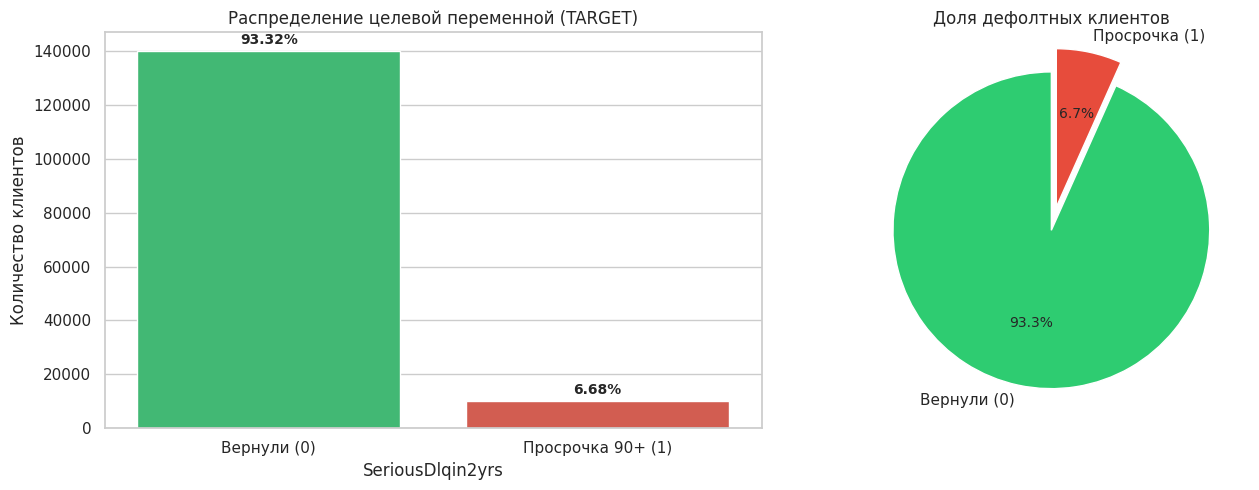

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='SeriousDlqin2yrs', data=df, ax=ax[0], palette=['#2ecc71', '#e74c3c'])
ax[0].set_title('Распределение целевой переменной (TARGET)')
ax[0].set_xticklabels(['Вернули (0)', 'Просрочка 90+ (1)'])
ax[0].set_ylabel('Количество клиентов')

total = len(df)
for p in ax[0].patches:
    percentage = f'{100 * p.get_height() / total:.2f}%'
    ax[0].annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points', weight='bold')

df['SeriousDlqin2yrs'].value_counts().plot.pie(
    explode=[0, 0.15], autopct='%1.1f%%', ax=ax[1], 
    colors=['#2ecc71', '#e74c3c'], labels=['Вернули (0)', 'Просрочка (1)'], startangle=90
)
ax[1].set_ylabel('')
ax[1].set_title('Доля дефолтных клиентов')

plt.tight_layout()
plt.show()

/tmp/ipykernel_16059/1927716470.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=missing.index, y=missing.values, palette='Blues_r')


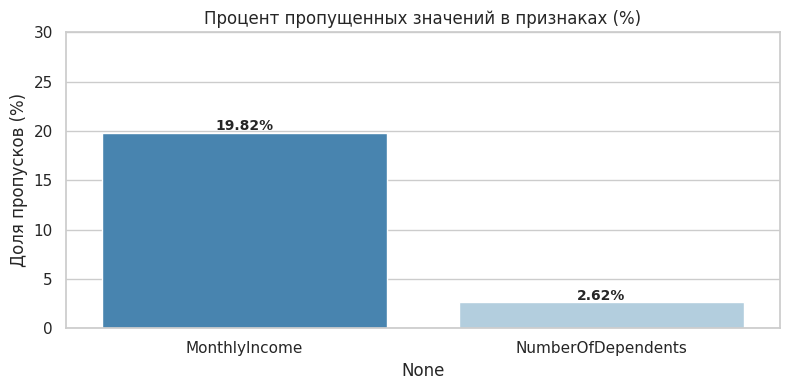

In [19]:
missing = df.isnull().sum()
missing = missing[missing > 0] / len(df) * 100

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=missing.index, y=missing.values, palette='Blues_r')
plt.title('Процент пропущенных значений в признаках (%)')
plt.ylabel('Доля пропусков (%)')
plt.ylim(0, 30)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', weight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_16059/3645058715.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  default_by_age = df_age.groupby('AgeGroup')['SeriousDlqin2yrs'].mean() * 100


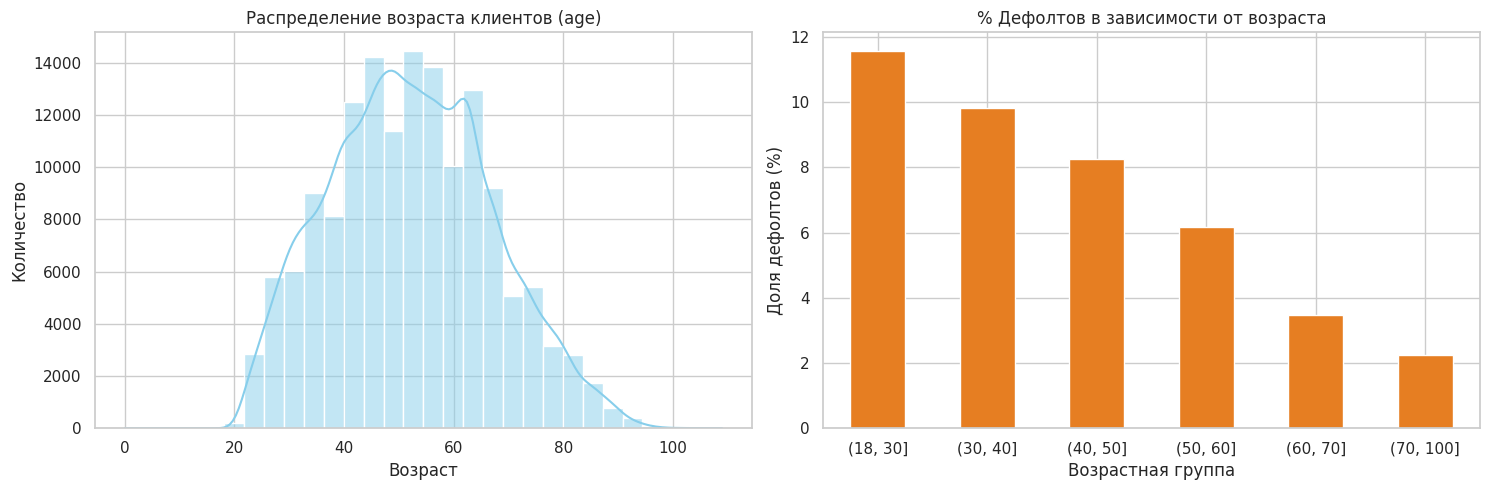

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x='age', bins=30, kde=True, color='skyblue', ax=ax[0])
ax[0].set_title('Распределение возраста клиентов (age)')
ax[0].set_xlabel('Возраст')
ax[0].set_ylabel('Количество')

df_age = df.copy()
df_age['AgeGroup'] = pd.cut(df_age['age'], bins=[18, 30, 40, 50, 60, 70, 100])
default_by_age = df_age.groupby('AgeGroup')['SeriousDlqin2yrs'].mean() * 100

default_by_age.plot(kind='bar', color='#e67e22', ax=ax[1])
ax[1].set_title('% Дефолтов в зависимости от возраста')
ax[1].set_xlabel('Возрастная группа')
ax[1].set_ylabel('Доля дефолтов (%)')
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

/tmp/ipykernel_16059/614875919.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='SeriousDlqin2yrs', data=df_temp, ax=ax[i], palette='Reds')
/tmp/ipykernel_16059/614875919.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='SeriousDlqin2yrs', data=df_temp, ax=ax[i], palette='Reds')
/tmp/ipykernel_16059/614875919.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=col, y='SeriousDlqin2yrs', data=df_temp, ax=ax[i], palette='Reds')


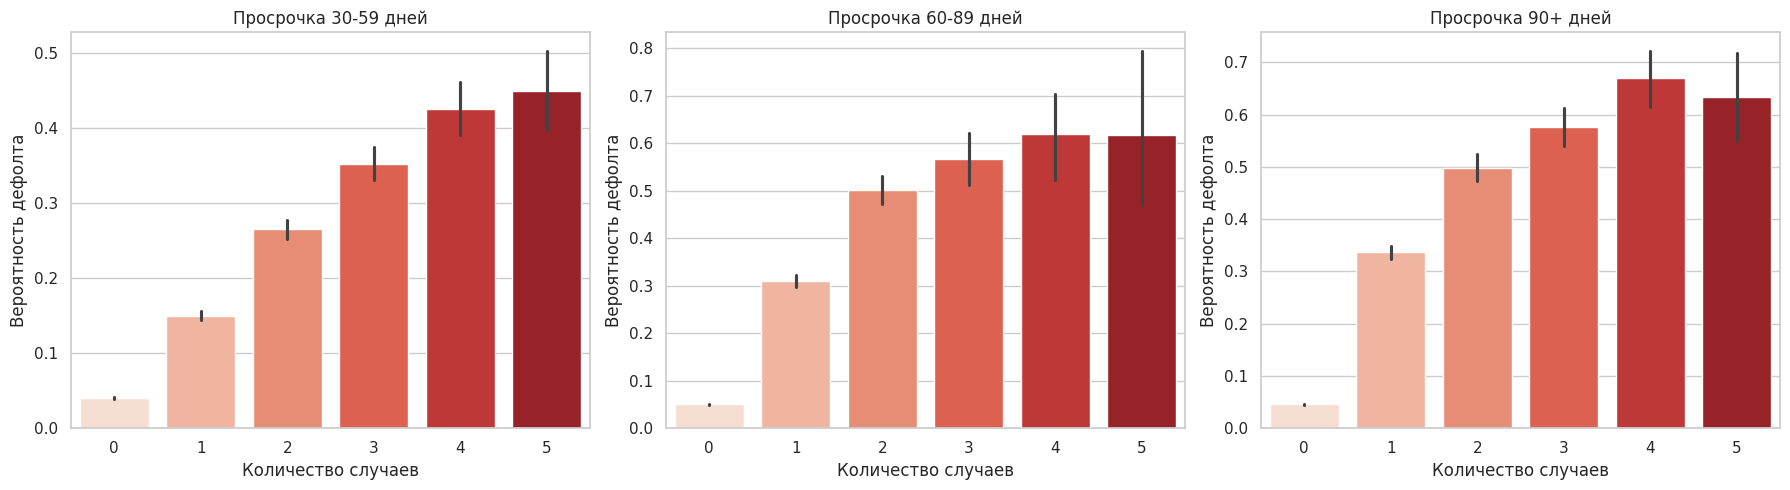

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

cols_past_due = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]
titles = ['Просрочка 30-59 дней', 'Просрочка 60-89 дней', 'Просрочка 90+ дней']

for i, col in enumerate(cols_past_due):
    df_temp = df[df[col] <= 5]
    sns.barplot(x=col, y='SeriousDlqin2yrs', data=df_temp, ax=ax[i], palette='Reds')
    ax[i].set_title(titles[i])
    ax[i].set_xlabel('Количество случаев')
    ax[i].set_ylabel('Вероятность дефолта')

plt.tight_layout()
plt.show()

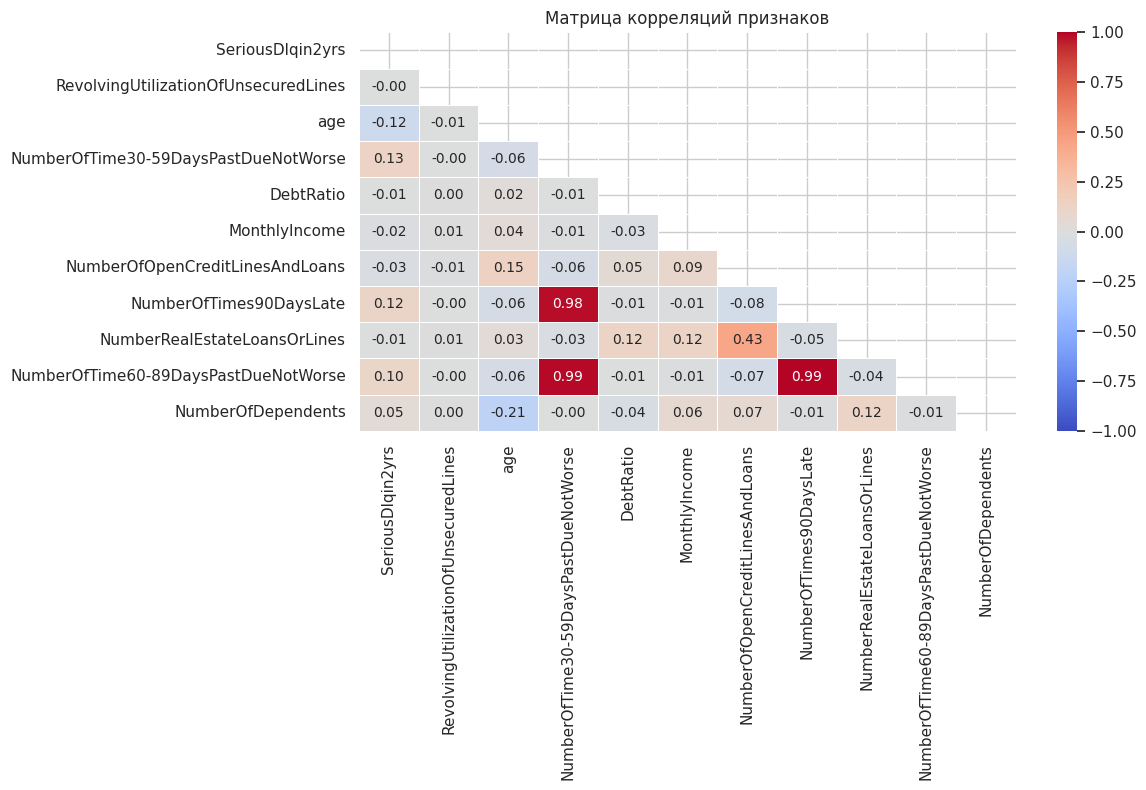

In [ ]:
plt.figure(figsize=(12, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Матрица корреляций признаков')
plt.tight_layout()
plt.show()